<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Custom embedddings con Gensim



### Objetivo
El objetivo es utilizar documentos / corpus para crear embeddings de palabras basado en ese contexto. Se utilizará canciones de bandas para generar los embeddings, es decir, que los vectores tendrán la forma en función de como esa banda haya utilizado las palabras en sus canciones.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import multiprocessing
try:
  from gensim.models import Word2Vec
except:
  !pip install gensim
  from gensim.models import Word2Vec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 37.2 MB/s  0:00:00


### Datos
Utilizaremos como dataset canciones de bandas de habla inglesa.

In [5]:
# Descargar la carpeta de dataset
import os
import platform
if os.access('./songs_dataset', os.F_OK) is False:
    if os.access('songs_dataset.zip', os.F_OK) is False:
        if platform.system() == 'Windows':
            !curl https://raw.githubusercontent.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/main/datasets/songs_dataset.zip -o songs_dataset.zip
        else:
            !wget songs_dataset.zip https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/raw/main/datasets/songs_dataset.zip
    !unzip -q songs_dataset.zip
else:
    print("El dataset ya se encuentra descargado")

--2026-11-12 23:32:25--  http://songs_dataset.zip/
Resolving songs_dataset.zip (songs_dataset.zip)... failed: Name or service not known.
wget: unable to resolve host address ‘songs_dataset.zip’
--2026-11-12 23:32:25--  https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/raw/main/datasets/songs_dataset.zip
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/main/datasets/songs_dataset.zip [following]
--2026-11-12 23:32:25--  https://raw.githubusercontent.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/main/datasets/songs_dataset.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.

In [6]:
# Posibles bandas
os.listdir("./songs_dataset/")

['michael-jackson.txt',
 'Lil_Wayne.txt',
 'amy-winehouse.txt',
 'nicki-minaj.txt',
 'lil-wayne.txt',
 'cake.txt',
 'bruno-mars.txt',
 'nirvana.txt',
 'britney-spears.txt',
 'dj-khaled.txt',
 'kanye.txt',
 'missy-elliott.txt',
 'eminem.txt',
 'nursery_rhymes.txt',
 'lin-manuel-miranda.txt',
 'drake.txt',
 'Kanye_West.txt',
 'blink-182.txt',
 'bieber.txt',
 'jimi-hendrix.txt',
 'paul-simon.txt',
 'disney.txt',
 'lady-gaga.txt',
 'lorde.txt',
 'ludacris.txt',
 'radiohead.txt',
 'nickelback.txt',
 'bjork.txt',
 'leonard-cohen.txt',
 'dr-seuss.txt',
 'beatles.txt',
 'kanye-west.txt',
 'bob-dylan.txt',
 'adele.txt',
 'johnny-cash.txt',
 'notorious_big.txt',
 'al-green.txt',
 'dolly-parton.txt',
 'joni-mitchell.txt',
 'bob-marley.txt',
 'patti-smith.txt',
 'alicia-keys.txt',
 'bruce-springsteen.txt',
 'prince.txt',
 'janisjoplin.txt',
 'notorious-big.txt',
 'r-kelly.txt',
 'rihanna.txt',
 'dickinson.txt']

In [7]:
# Armar el dataset utilizando salto de línea para separar las oraciones/docs
df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)
df.head()

/tmp/ipykernel_6942/3849064916.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)


,0
0,"Yesterday, all my troubles seemed so far away"
1,Now it looks as though they're here to stay
2,"Oh, I believe in yesterday Suddenly, I'm not h..."
3,There's a shadow hanging over me.
4,"Oh, yesterday came suddenly Why she had to go ..."


In [8]:
print("Cantidad de documentos:", df.shape[0])

Cantidad de documentos: 1846


### 1 - Preprocesamiento

In [9]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

sentence_tokens = []
# Recorrer todas las filas y transformar las oraciones
# en una secuencia de palabras (esto podría realizarse con NLTK o spaCy también)
for _, row in df[:None].iterrows():
    sentence_tokens.append(text_to_word_sequence(row[0]))

In [10]:
# Demos un vistazo
sentence_tokens[:2]

[['yesterday', 'all', 'my', 'troubles', 'seemed', 'so', 'far', 'away'],
 ['now', 'it', 'looks', 'as', 'though', "they're", 'here', 'to', 'stay']]

### 2 - Crear los vectores (word2vec)

In [11]:
from gensim.models.callbacks import CallbackAny2Vec
# Durante el entrenamiento gensim por defecto no informa el "loss" en cada época
# Sobrecargamos el callback para poder tener esta información
class callback(CallbackAny2Vec):
    """
    Callback to print loss after each epoch
    """
    def __init__(self):
        self.epoch = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        if self.epoch == 0:
            print('Loss after epoch {}: {}'.format(self.epoch, loss))
        else:
            print('Loss after epoch {}: {}'.format(self.epoch, loss- self.loss_previous_step))
        self.epoch += 1
        self.loss_previous_step = loss

In [12]:
# Crearmos el modelo generador de vectores
# En este caso utilizaremos la estructura modelo Skipgram
w2v_model = Word2Vec(min_count=5,    # frecuencia mínima de palabra para incluirla en el vocabulario
                     window=2,       # cant de palabras antes y desp de la predicha
                     vector_size=300,       # dimensionalidad de los vectores
                     negative=20,    # cantidad de negative samples... 0 es no se usa
                     workers=1,      # si tienen más cores pueden cambiar este valor
                     sg=1)           # modelo 0:CBOW  1:skipgram

In [13]:
# Obtener el vocabulario con los tokens
w2v_model.build_vocab(sentence_tokens)

In [14]:
# Cantidad de filas/docs encontradas en el corpus
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)

Cantidad de docs en el corpus: 1846


In [15]:
# Cantidad de words encontradas en el corpus
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de words distintas en el corpus: 445


### 3 - Entrenar embeddings

In [16]:
# Entrenamos el modelo generador de vectores
# Utilizamos nuestro callback
w2v_model.train(sentence_tokens,
                 total_examples=w2v_model.corpus_count,
                 epochs=20,
                 compute_loss = True,
                 callbacks=[callback()]
                 )

Loss after epoch 0: 113045.25
Loss after epoch 1: 65966.59375
Loss after epoch 2: 65934.984375
Loss after epoch 3: 65718.390625
Loss after epoch 4: 63875.09375
Loss after epoch 5: 64160.65625
Loss after epoch 6: 64080.21875
Loss after epoch 7: 64814.875
Loss after epoch 8: 62632.75
Loss after epoch 9: 60452.875
Loss after epoch 10: 59839.875
Loss after epoch 11: 58884.375
Loss after epoch 12: 57715.75
Loss after epoch 13: 56494.3125
Loss after epoch 14: 55817.5
Loss after epoch 15: 55842.9375
Loss after epoch 16: 51722.4375
Loss after epoch 17: 49858.0
Loss after epoch 18: 49592.25
Loss after epoch 19: 48960.125


(156986, 287740)

### 4 - Ensayar

In [17]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["darling"], topn=10)

[('pretty', 0.8954247832298279),
 ('sleep', 0.8665655851364136),
 ('help', 0.8439376354217529),
 ('cry', 0.8351269960403442),
 ('not', 0.8309612274169922),
 ('try', 0.8276943564414978),
 ('peace', 0.8144856691360474),
 ('little', 0.8140572309494019),
 ('twist', 0.8123919367790222),
 ('seems', 0.8079564571380615)]

In [18]:
# Palabras que MENOS se relacionan con...:
w2v_model.wv.most_similar(negative=["love"], topn=10)

[('shake', -0.22873197495937347),
 ('four', -0.2330218255519867),
 ('five', -0.23746445775032043),
 ('six', -0.23784494400024414),
 ('bang', -0.24832050502300262),
 ('our', -0.25539135932922363),
 ('day', -0.2689811885356903),
 ('going', -0.2692062556743622),
 ('here', -0.26990723609924316),
 ('three', -0.2838989198207855)]

In [19]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["four"], topn=10)

[('five', 0.9813723564147949),
 ('three', 0.9745770692825317),
 ('six', 0.9710808992385864),
 ('seven', 0.9584357738494873),
 ('two', 0.9517216682434082),
 ('sixty', 0.8990395665168762),
 ('one', 0.7951181530952454),
 ('crying', 0.7946289777755737),
 ('us', 0.7740051746368408),
 ("i'm", 0.7508383393287659)]

In [20]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["money"], topn=5)

[("can't", 0.9434017539024353),
 ('buy', 0.9396998882293701),
 ('much', 0.9033146500587463),
 ('just', 0.8509082198143005),
 ('hide', 0.835538387298584)]

In [22]:
# Ensayar con una palabra que no está en el vocabulario:
w2v_model.wv.most_similar(negative=["diedaa"])

KeyError: "Key 'diedaa' not present in vocabulary"

In [23]:
# el método `get_vector` permite obtener los vectores:
vector_love = w2v_model.wv.get_vector("love")
print(vector_love)

[ 0.06138203  0.05881222 -0.06370417  0.02444947 -0.20152196 -0.18612292
 -0.15284595  0.4548753  -0.04217871  0.03536078  0.13657516 -0.18520005
 -0.1812647   0.22149836 -0.3038084  -0.23970386  0.07094695 -0.05679139
 -0.05166207 -0.23843557 -0.08530281  0.19564727 -0.07678778  0.03797247
  0.07517307 -0.04826551  0.07379535  0.10396848  0.00738022 -0.22764729
 -0.0456724   0.12937619  0.27785638  0.19387618 -0.13509148  0.20857106
  0.40917322 -0.00387122 -0.1063128  -0.09056759  0.02400028 -0.0800491
  0.13400665  0.08833536 -0.01894405  0.08592905 -0.15905626  0.10259357
  0.14459287 -0.12092585 -0.27919102 -0.04061577  0.11382084  0.31365854
 -0.07409792  0.13976744  0.22791271  0.13209458 -0.01811365  0.09772275
  0.09249583 -0.14871688 -0.16348091 -0.13203284 -0.09834065  0.02714608
  0.16531324  0.26051944 -0.0325964  -0.02894551  0.11621328 -0.06974234
  0.09563565 -0.15276384  0.22071053  0.15996666  0.1589048  -0.04711676
 -0.12555045 -0.03993924 -0.10795183  0.01878959  0.

In [24]:
# el método `most_similar` también permite comparar a partir de vectores
w2v_model.wv.most_similar(vector_love)

[('love', 0.9999999403953552),
 ('babe', 0.9085132479667664),
 ('someone', 0.8886148929595947),
 ('need', 0.8827974200248718),
 ('nothing', 0.8740269541740417),
 ("didn't", 0.8638361096382141),
 ("there's", 0.8526672720909119),
 ('you', 0.8456704616546631),
 ('feed', 0.8445017337799072),
 ('somebody', 0.8362804651260376)]

In [25]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["love"], topn=10)

[('babe', 0.9085132479667664),
 ('someone', 0.8886148929595947),
 ('need', 0.8827974200248718),
 ('nothing', 0.8740269541740417),
 ("didn't", 0.8638360500335693),
 ("there's", 0.8526672720909119),
 ('you', 0.8456703424453735),
 ('feed', 0.8445016741752625),
 ('somebody', 0.8362804651260376),
 ('buy', 0.8351694941520691)]

### 5 - Visualizar agrupación de vectores

In [26]:
from sklearn.decomposition import IncrementalPCA
from sklearn.manifold import TSNE
import numpy as np

def reduce_dimensions(model, num_dimensions = 2 ):

    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    return vectors, labels

In [27]:
# Graficar los embedddings en 2D
import plotly.graph_objects as go
import plotly.express as px

vecs, labels = reduce_dimensions(w2v_model)

MAX_WORDS=200
fig = px.scatter(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], text=labels[:MAX_WORDS])
fig.show(renderer="colab") # esto para plotly en colab

In [28]:
# Graficar los embedddings en 3D

vecs, labels = reduce_dimensions(w2v_model,3)

fig = px.scatter_3d(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], z=vecs[:MAX_WORDS,2],text=labels[:MAX_WORDS])
fig.update_traces(marker_size = 2)
fig.show(renderer="colab") # esto para plotly en colab

In [29]:
# También se pueden guardar los vectores y labels como tsv para graficar en
# http://projector.tensorflow.org/


vectors = np.asarray(w2v_model.wv.vectors)
labels = list(w2v_model.wv.index_to_key)

np.savetxt("vectors.tsv", vectors, delimiter="\t")

with open("labels.tsv", "w") as fp:
    for item in labels:
        fp.write("%s\n" % item)

### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

#Desafio 2

Use el corpus de la novela Orgullo y perjuicio de Jane Austen, descargada de https://www.textos.info/
Elegi esta novela porque hay mucho vocabulario de parentesco (hermana, madre, tía, sobrina), de tratamiento (señor, señora, señorita) y de personajes, que son buenos terminos para explorar.


In [92]:
import os
import re
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from gensim.models import Word2Vec
except:
    !pip install gensim
    from gensim.models import Word2Vec

from gensim.utils import simple_preprocess
from sklearn.manifold import TSNE

In [93]:
import os, urllib.request

ARCHIVO = "orgullo_y_prejuicio.txt"
URL = "https://raw.githubusercontent.com/RocioFioranelli/nlp-desafio2/main/orgullo_y_prejuicio.txt"
if not os.path.exists(ARCHIVO):
    urllib.request.urlretrieve(URL, ARCHIVO)

with open(ARCHIVO, encoding="utf-8") as f:
    texto = f.read()

print("Palabras (aprox.):", len(texto.split()))

Palabras (aprox.): 115092


En este texto cada renglon es un parrafo entero, asi que si tomara cada renglon como una oracion tendria unos documentos muy largos y muy poco ejemplos para entrenar, por eso separo el texto en oraciones de verdad.
Normalizo espacios y separo en oraciones con una expresion regular.
Tokenizo cada oracion con simple_preprocess de Gensim. Uso min_len=1 para no perder palabras cortas importantes y conservo tildes porque en español cambia el significado.

In [94]:
t = re.sub(r"Capítulo [IVXLC]+", " ", texto)
t = re.sub(r"[—–]", " ", t)
t = re.sub(r"\s+", " ", t)

oraciones = re.split(r"(?<=[.!?…])\s+", t)
sentence_tokens = [simple_preprocess(o, min_len=1) for o in oraciones]
sentence_tokens = [s for s in sentence_tokens if len(s) >= 3]

print("Cantidad de oraciones:", len(sentence_tokens))
print("Cantidad de tokens:", sum(len(s) for s in sentence_tokens))

Cantidad de oraciones: 5901
Cantidad de tokens: 114563


In [95]:
def hashfxn(s):
    return zlib.crc32(s.encode("utf-8"))

w2v_model = Word2Vec(sentence_tokens, sg=0, window=5, vector_size=100, negative=10,
                     min_count=5, workers=1, seed=42, hashfxn=hashfxn, epochs=30)


#se utiliza vector size=100 para un vocabulario de 2000 palabras. min_count=5 para descartar palabras  con muy pocos ejemplos porque sus vectores no serian confiables.

print("Palabras en el vocabulario:", len(w2v_model.wv.index_to_key))

Palabras en el vocabulario: 2135


In [96]:
#palabras mas similares

def vecinos(palabra, topn=8):
    res = w2v_model.wv.most_similar(positive=[palabra], topn=topn)
    return pd.DataFrame(res, columns=[f"vecinos de '{palabra}'", "cos"]).round(3)

for p in ["darcy", "elizabeth", "hermana", "matrimonio", "orgullo"]:
    display(vecinos(p))

,vecinos de 'darcy',cos
0,bingley,0.836
1,wickham,0.692
2,bennet,0.637
3,collins,0.597
4,hurst,0.587
5,gardiner,0.568
6,él,0.541
7,bourgh,0.493


,vecinos de 'elizabeth',cos
0,calma,0.607
1,levantó,0.606
2,jane,0.600
3,inmediatamente,0.595
4,sonrisa,0.595
5,voz,0.583
6,georgiana,0.581
7,ella,0.564


,vecinos de 'hermana',cos
0,amigo,0.782
1,marido,0.708
2,sobrina,0.692
3,padre,0.688
4,señoría,0.645
5,prima,0.641
6,tío,0.641
7,tía,0.624


,vecinos de 'matrimonio',cos
0,comportamiento,0.753
1,asunto,0.729
2,afecto,0.720
3,estilo,0.680
4,objeto,0.665
5,caso,0.648
6,amor,0.632
7,orgullo,0.624


,vecinos de 'orgullo',cos
0,sentido,0.687
1,inteligencia,0.678
2,talento,0.669
3,carácter,0.657
4,juicio,0.649
5,comportamiento,0.647
6,generoso,0.637
7,beneficio,0.630


In [97]:
#palabras menos similares

for p in ["amor", "hermana"]:
    display(pd.DataFrame(w2v_model.wv.most_similar(negative=[p], topn=6),
                         columns=[f"lo más opuesto a '{p}'", "cos"]).round(3))


,lo más opuesto a 'amor',cos
0,iban,0.414
1,mujeres,0.396
2,menores,0.372
3,mayores,0.351
4,señoras,0.340
5,fueron,0.337


,lo más opuesto a 'hermana',cos
0,nuestra,0.324
1,unos,0.317
2,cuantos,0.278
3,una,0.252
4,quince,0.249
5,media,0.246


Lo "mas opuesto" a amor son iban, mujeres, menores, mayores, señoras, fueron, y a hermana son nuestra, unos, cuantos, una. No son antonimos (lo contrario de amor no es iban): son palabras que casi nunca comparten contexto con la palabra buscada, generalmente plurales y verbos. Word2Vec aprende solo cercanía de uso, así que "menos similar" no significa "significa lo contrario".

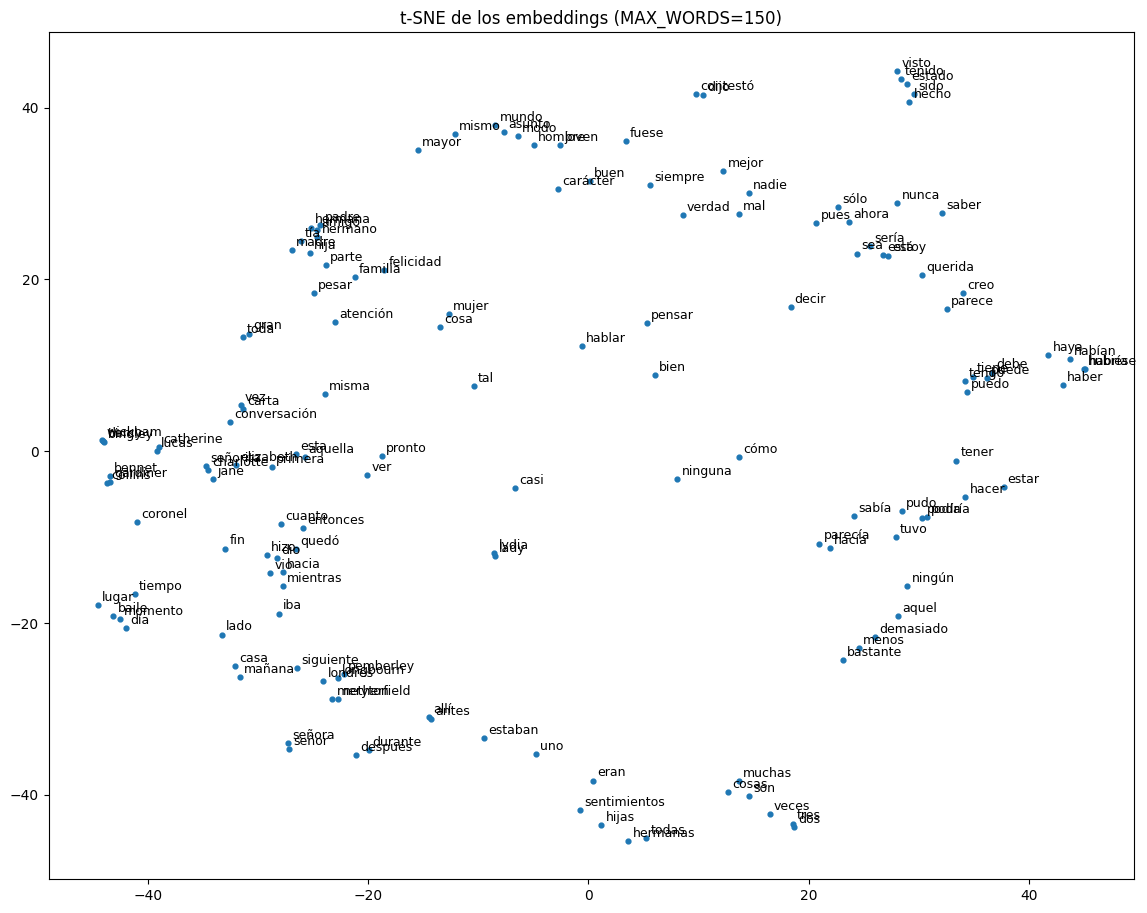

In [98]:
#reduzco los vectores de 100 a 2 dimensiones con t-SNE. Saco las stopwords solo para graficar, porque son las palabras mas frecuentes y taparian el grafico.

STOPWORDS_ES = set("""de que la a y no en su el se con lo por le pero los para una más las un al me había es sus si
como mi era sin ha muy tan ni o esto yo te mis hay ya sobre este tenía les ese eso esa estaba fue ser han todo todos
nos cuando donde también así hasta qué quien quién cuál porque aunque entre desde otro otra otros otras algo nada tanto
mucho poco ella él ellos ellas usted del cual cuyo""".split())

palabras = [w for w in w2v_model.wv.index_to_key if w not in STOPWORDS_ES and len(w) > 2]
vectores = np.array([w2v_model.wv[w] for w in palabras])

tsne = TSNE(n_components=2, random_state=0, perplexity=20, init="pca", learning_rate="auto")
vecs_2d = tsne.fit_transform(vectores)

MAX_WORDS = 150 #con 400 palabras el grafico era ilegible, pero con 150 se pueden leer casi todas y todavia hay suficientes palabras para ver agrupaciones
plt.figure(figsize=(14, 11))
plt.scatter(vecs_2d[:MAX_WORDS, 0], vecs_2d[:MAX_WORDS, 1], s=12)
for (x, y), w in zip(vecs_2d[:MAX_WORDS], palabras[:MAX_WORDS]):
    plt.annotate(w, (x, y), fontsize=9, xytext=(3, 3), textcoords="offset points")
plt.title(f"t-SNE de los embeddings (MAX_WORDS={MAX_WORDS})")
plt.show()

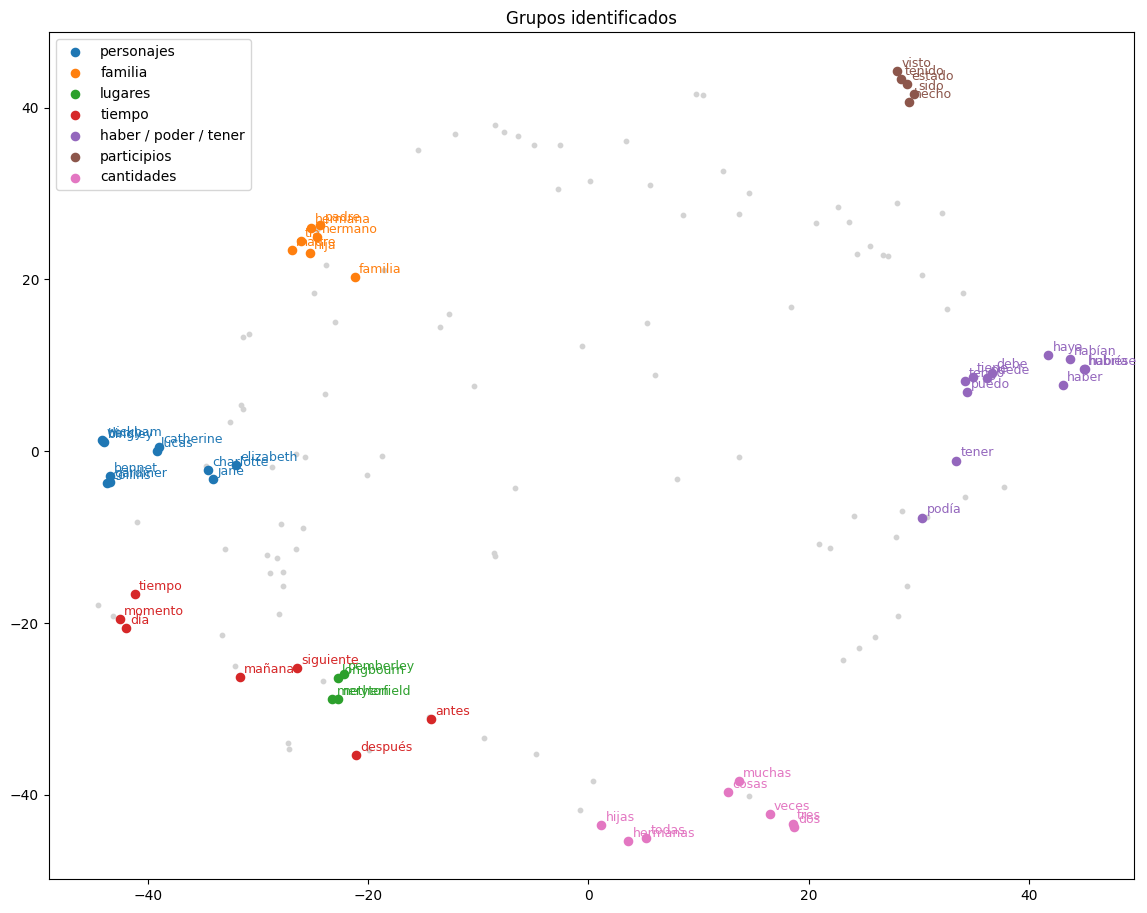

In [99]:
# marco con colores los grupos que encontre en el grafico.

grupos = {
    "personajes": "elizabeth darcy bingley bennet jane wickham collins catherine gardiner charlotte lucas".split(),
    "familia": "padre madre hermana hermano hija familia tía".split(),
    "lugares": "pemberley netherfield meryton longbourn".split(),
    "tiempo": "mañana día momento tiempo siguiente después antes".split(),
    "haber / poder / tener": "habría hubiese haya haber habían debe puede puedo podía tiene tengo tener".split(),
    "participios": "hecho visto sido estado tenido".split(),
    "cantidades": "dos tres veces muchas todas cosas hermanas hijas".split(),
}
idx = {w: i for i, w in enumerate(palabras[:MAX_WORDS])}

plt.figure(figsize=(14, 11))
plt.scatter(vecs_2d[:MAX_WORDS, 0], vecs_2d[:MAX_WORDS, 1], s=10, color="lightgray")
for (g, ws), col in zip(grupos.items(), plt.cm.tab10.colors):
    pts = [idx[w] for w in ws if w in idx]
    plt.scatter(vecs_2d[pts, 0], vecs_2d[pts, 1], s=35, color=col, label=g)
    for i in pts:
        plt.annotate(palabras[i], vecs_2d[i], fontsize=9, color=col, xytext=(3, 3), textcoords="offset points")
plt.legend()
plt.title("Grupos identificados")
plt.show()

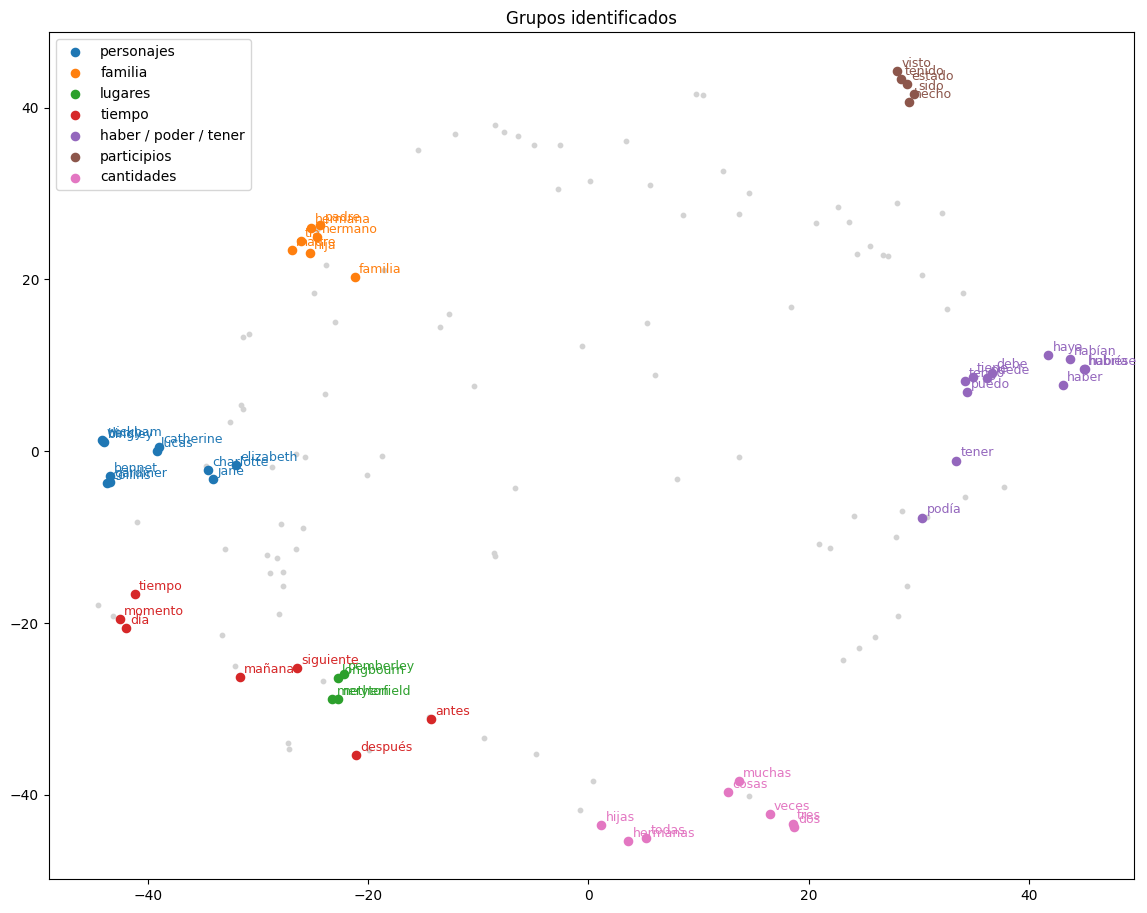
Personajes (elizabeth, darcy, bingley, bennet...), familia (padre, madre, hermana, tía...) y lugares (pemberley, netherfield, meryton, longbourn)quedan agrupados porque aparecen en contextos parecidos. Los grupos haber / poder / tener y participios son gramaticales y no de significado: el modelo tambien agrupa palabras que cumplen la misma funcion. Hermanas e hijas quedan lejos de hermana e hija, cerca de muchas, todas y veces parece que pesa mas ser plural que el tema familiar.

Conclusion:


*   Con un corpus chico elegí hiperparametros más livianos: CBOW, 100 dimensiones y 5 de ventana.
*   Los vecinos tienen sentido, por ejemplo darcy con bingley y orgullo con cualidades de las personas, pero los embeddings capturan uso en contexto y no significado: elizabeth queda cerca de gestos y acciones, y lo "opuesto" a amor son plurales y verbos, no antonimos.
*  Las palabras poco frecuentes dan resultados pobres: prejuicio ni entro al vocabulario con min_count=5
*  t-SNE sirve para explorar, pero es estocastico y el grafico puede variar entre corridas. Con mas texto los grupos tematicos deberían quedar mas definidos.
